# Air Quality in India: Patterns, Pollutants and the COVID-19 Lockdown Effect

**Objective:** This project analyses daily air quality data from 26 Indian cities (2015-2020) to find out which cities, seasons and pollutants have the worst air quality. It also checks whether the 2020 COVID-19 lockdown reduced pollution, so that pollution control efforts can be focused where they matter most.

**Dataset:** city_day.csv, Central Pollution Control Board (CPCB), 26 cities, 2015-2020


**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn

**Author:** [Kamatham Sneha] | October 2026 

## Load and understand the data

In [155]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [156]:
df=pd.read_csv('city_day.csv')

In [157]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory


In [158]:
df.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')

In [159]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


**Missing value Columns:**  Xylene , PM10 , NH3	, Toluene , Benzene , AQI	4 , AQI_Bucket	, PM2.5	, NOx	, O3	, SO2	, NO2	, NO	, CO

## Data Cleaning


In [160]:
df["Date"] = pd.to_datetime(df["Date"])

In [161]:
df.isna().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [162]:
df=df.drop(columns=["Xylene","Benzene", "Toluene"])

In [163]:
df=df.dropna(subset=["AQI"])

In [164]:
df=df.dropna(subset=["AQI_Bucket"])

In [165]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket
28,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,209.0,Poor
29,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,328.0,Very Poor
30,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,514.0,Severe
31,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,782.0,Severe
32,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,914.0,Severe
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,54.0,Satisfactory


In [166]:
df.info()

<class 'pandas.DataFrame'>
Index: 24850 entries, 28 to 29530
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        24850 non-null  str           
 1   Date        24850 non-null  datetime64[us]
 2   PM2.5       24172 non-null  float64       
 3   PM10        17764 non-null  float64       
 4   NO          24463 non-null  float64       
 5   NO2         24459 non-null  float64       
 6   NOx         22993 non-null  float64       
 7   NH3         18314 non-null  float64       
 8   CO          24405 non-null  float64       
 9   SO2         24245 non-null  float64       
 10  O3          24043 non-null  float64       
 11  AQI         24850 non-null  float64       
 12  AQI_Bucket  24850 non-null  str           
dtypes: datetime64[us](1), float64(10), str(2)
memory usage: 2.7 MB


In [167]:
df.duplicated().any()

np.False_

In [168]:
cols_to_fill = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]

for col in cols_to_fill:
    df[col] = df[col].fillna(df.groupby("City")[col].transform("median"))

In [169]:
print(df.isna().sum())

City             0
Date             0
PM2.5            0
PM10          1893
NO               0
NO2              0
NOx            771
NH3           1334
CO               0
SO2              0
O3             153
AQI              0
AQI_Bucket       0
dtype: int64


In [170]:
for col in ["PM10", "NOx", "NH3", "O3"]:
    df[col] = df[col].fillna(df[col].median())

In [171]:
print(df.isna().sum())  


City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
AQI           0
AQI_Bucket    0
dtype: int64


In [172]:
df = df.reset_index(drop=True)
df.to_csv("cleaned_data.csv", index=False)

## Data Transformation

In [173]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df["Day_of_Week"] = df["Date"].dt.day_name()
df['Month_Name'] = df['Date'].dt.month_name()

In [174]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Day_of_Week,Month_Name
0,Ahmedabad,2015-01-29,83.13,107.67,6.93,28.71,33.72,17.055,6.93,49.52,59.76,209.0,Poor,2015,1,Thursday,January
1,Ahmedabad,2015-01-30,79.84,107.67,13.85,28.68,41.08,17.055,13.85,48.49,97.07,328.0,Very Poor,2015,1,Friday,January
2,Ahmedabad,2015-01-31,94.52,107.67,24.39,32.66,52.61,17.055,24.39,67.39,111.33,514.0,Severe,2015,1,Saturday,January
3,Ahmedabad,2015-02-01,135.99,107.67,43.48,42.08,84.57,17.055,43.48,75.23,102.70,782.0,Severe,2015,2,Sunday,February
4,Ahmedabad,2015-02-02,178.33,107.67,54.56,35.31,72.80,17.055,54.56,55.04,107.38,914.0,Severe,2015,2,Monday,February
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.470,0.47,8.55,23.30,41.0,Good,2020,6,Saturday,June
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.990,0.52,12.72,30.14,70.0,Satisfactory,2020,6,Sunday,June
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.710,0.48,8.42,30.96,68.0,Satisfactory,2020,6,Monday,June
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.030,0.52,9.84,28.30,54.0,Satisfactory,2020,6,Tuesday,June


In [175]:
def get_season(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Summer"
    elif m in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

In [176]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Day_of_Week,Month_Name,Season
0,Ahmedabad,2015-01-29,83.13,107.67,6.93,28.71,33.72,17.055,6.93,49.52,59.76,209.0,Poor,2015,1,Thursday,January,Winter
1,Ahmedabad,2015-01-30,79.84,107.67,13.85,28.68,41.08,17.055,13.85,48.49,97.07,328.0,Very Poor,2015,1,Friday,January,Winter
2,Ahmedabad,2015-01-31,94.52,107.67,24.39,32.66,52.61,17.055,24.39,67.39,111.33,514.0,Severe,2015,1,Saturday,January,Winter
3,Ahmedabad,2015-02-01,135.99,107.67,43.48,42.08,84.57,17.055,43.48,75.23,102.70,782.0,Severe,2015,2,Sunday,February,Winter
4,Ahmedabad,2015-02-02,178.33,107.67,54.56,35.31,72.80,17.055,54.56,55.04,107.38,914.0,Severe,2015,2,Monday,February,Winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.470,0.47,8.55,23.30,41.0,Good,2020,6,Saturday,June,Monsoon
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.990,0.52,12.72,30.14,70.0,Satisfactory,2020,6,Sunday,June,Monsoon
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.710,0.48,8.42,30.96,68.0,Satisfactory,2020,6,Monday,June,Monsoon
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.030,0.52,9.84,28.30,54.0,Satisfactory,2020,6,Tuesday,June,Monsoon


In [177]:
print(df["Date"].min(), df["Date"].max())

2015-01-01 00:00:00 2020-07-01 00:00:00


In [178]:
def get_period(d):
    if d < pd.Timestamp("2020-03-25"):
        return "Pre-Lockdown"
    elif d <= pd.Timestamp("2020-05-31"):
        return "Lockdown"
    else:
        return "Post-Lockdown"

df["Period"] = df["Date"].apply(get_period)

In [179]:
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Day_of_Week,Month_Name,Season,Period
0,Ahmedabad,2015-01-29,83.13,107.67,6.93,28.71,33.72,17.055,6.93,49.52,59.76,209.0,Poor,2015,1,Thursday,January,Winter,Pre-Lockdown
1,Ahmedabad,2015-01-30,79.84,107.67,13.85,28.68,41.08,17.055,13.85,48.49,97.07,328.0,Very Poor,2015,1,Friday,January,Winter,Pre-Lockdown
2,Ahmedabad,2015-01-31,94.52,107.67,24.39,32.66,52.61,17.055,24.39,67.39,111.33,514.0,Severe,2015,1,Saturday,January,Winter,Pre-Lockdown
3,Ahmedabad,2015-02-01,135.99,107.67,43.48,42.08,84.57,17.055,43.48,75.23,102.70,782.0,Severe,2015,2,Sunday,February,Winter,Pre-Lockdown
4,Ahmedabad,2015-02-02,178.33,107.67,54.56,35.31,72.80,17.055,54.56,55.04,107.38,914.0,Severe,2015,2,Monday,February,Winter,Pre-Lockdown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24845,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.470,0.47,8.55,23.30,41.0,Good,2020,6,Saturday,June,Monsoon,Post-Lockdown
24846,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.990,0.52,12.72,30.14,70.0,Satisfactory,2020,6,Sunday,June,Monsoon,Post-Lockdown
24847,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.710,0.48,8.42,30.96,68.0,Satisfactory,2020,6,Monday,June,Monsoon,Post-Lockdown
24848,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.030,0.52,9.84,28.30,54.0,Satisfactory,2020,6,Tuesday,June,Monsoon,Post-Lockdown


In [180]:
print(df[["Date", "Year", "Month_Name", "Season", "Period"]].head())
print(df["Period"].value_counts())
print(df["Season"].value_counts())

        Date  Year Month_Name  Season        Period
0 2015-01-29  2015    January  Winter  Pre-Lockdown
1 2015-01-30  2015    January  Winter  Pre-Lockdown
2 2015-01-31  2015    January  Winter  Pre-Lockdown
3 2015-02-01  2015   February  Winter  Pre-Lockdown
4 2015-02-02  2015   February  Winter  Pre-Lockdown
Period
Pre-Lockdown     22422
Lockdown          1668
Post-Lockdown      760
Name: count, dtype: int64
Season
Monsoon         7713
Summer          7069
Winter          6243
Post-Monsoon    3825
Name: count, dtype: int64


## Visualization

In [181]:
monthly = df.groupby(df["Date"].dt.to_period("M"))["AQI"].mean()
monthly.index = monthly.index.to_timestamp()

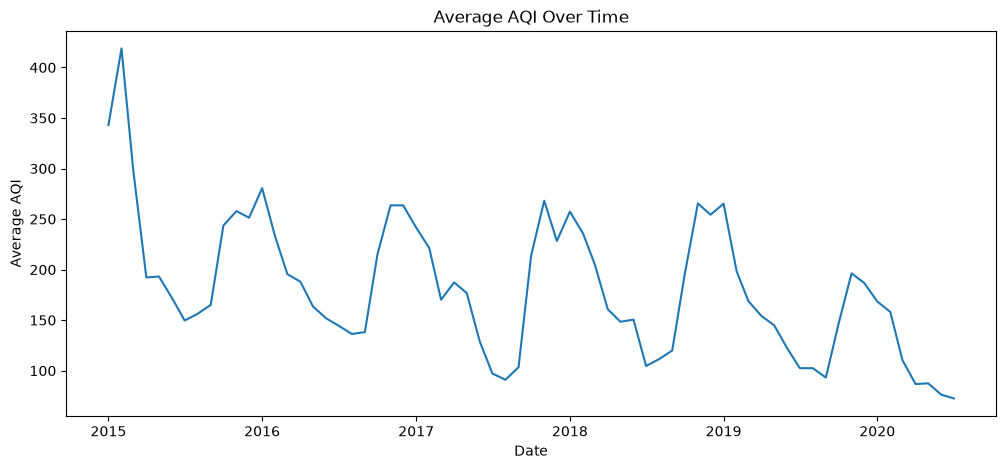

In [182]:
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values)
plt.title("Average AQI Over Time")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.show()

**OBSERVATION:** 

AQI goes up and down in the same pattern every year. It is high in winter and low in the monsoon. The winter peak in 2020 is lower than in earlier years.

In [183]:
top_cities = df.groupby("City")["AQI"].median().sort_values(ascending=False).head(10)

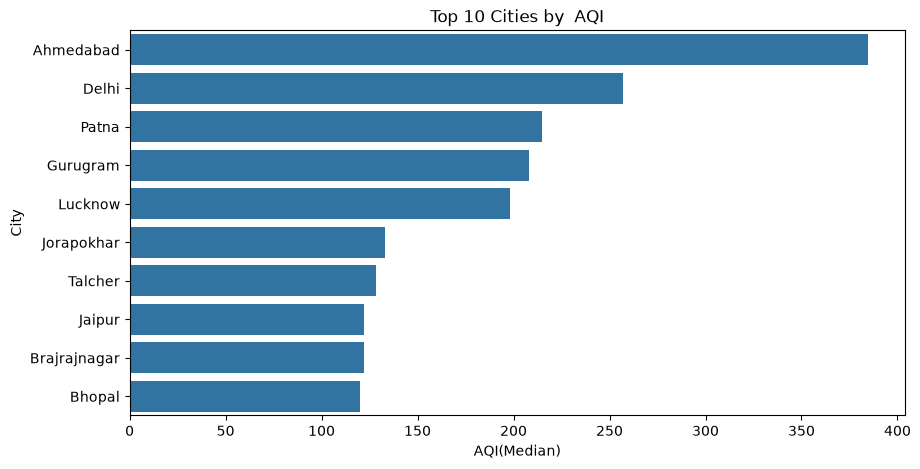

In [184]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_cities.values, y=top_cities.index)
plt.title("Top 10 Cities by  AQI")
plt.xlabel("AQI(Median)")
plt.show()

**OBSERVATION:**

Ahmedabad has the highest AQI followed by Delhi, Patna, Gurugram and Lucknow. I used the median because Ahmedabad has some extremely high values.

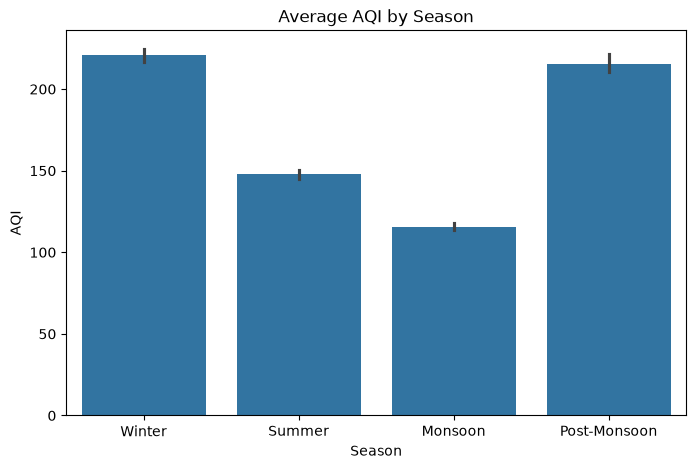

In [185]:
season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Season", y="AQI", order=season_order)
plt.title("Average AQI by Season")
plt.show()

**OBSERVATION:**

Winter and post-monsoon have the highest AQI. The monsoon has the lowest, because rain cleans the air.

In [186]:
Lockdown_period = df[((df["Month"] == 3) & (df["Date"].dt.day >= 25)) | (df["Month"].isin([4, 5]))]

In [187]:
years_per_city = Lockdown_period.groupby("City")["Year"].nunique()

In [188]:
full_cities = years_per_city[years_per_city == Lockdown_period["Year"].nunique()].index

In [189]:
Lockdown_period_fair = Lockdown_period[Lockdown_period["City"].isin(full_cities)]
yearly_fair = Lockdown_period_fair.groupby("Year")["AQI"].mean().round(1)
print(yearly_fair)

Year
2015    179.0
2016    164.2
2017    178.9
2018    145.8
2019    149.3
2020     89.8
Name: AQI, dtype: float64


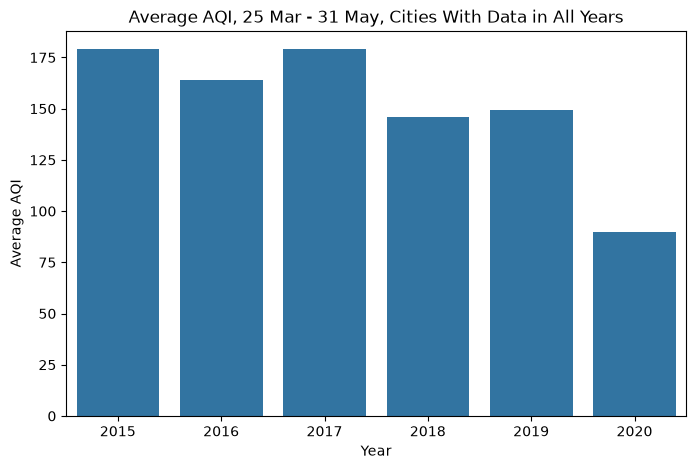

In [190]:
plt.figure(figsize=(8, 5))
sns.barplot(x=yearly_fair.index, y=yearly_fair.values)
plt.title("Average AQI, 25 Mar - 31 May, Cities With Data in All Years")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.show()

**OBSERVATION:**

The average AQI was 149.3 in 2019 and 89.8 in 2020. That is a fall of about 40% during the lockdown.

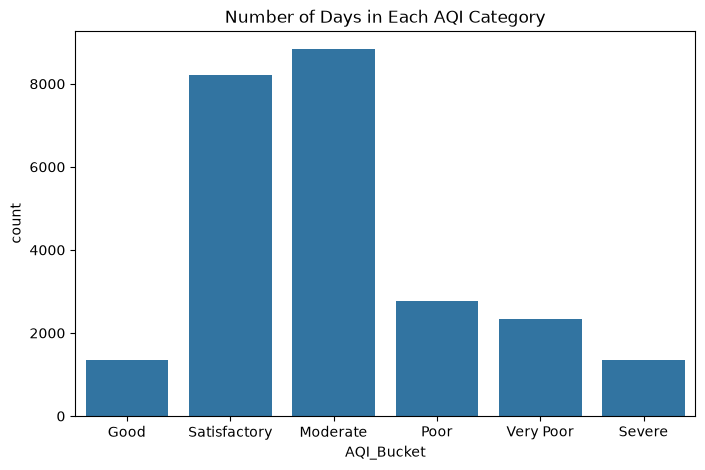

In [191]:
bucket_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="AQI_Bucket", order=bucket_order)
plt.title("Number of Days in Each AQI Category")
plt.show()

**OBSERVATION:**

Most days are Satisfactory or Moderate. Very few days are Good, and a small number are Severe.

In [192]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "AQI"]

In [193]:
table=df[pollutants].corr()

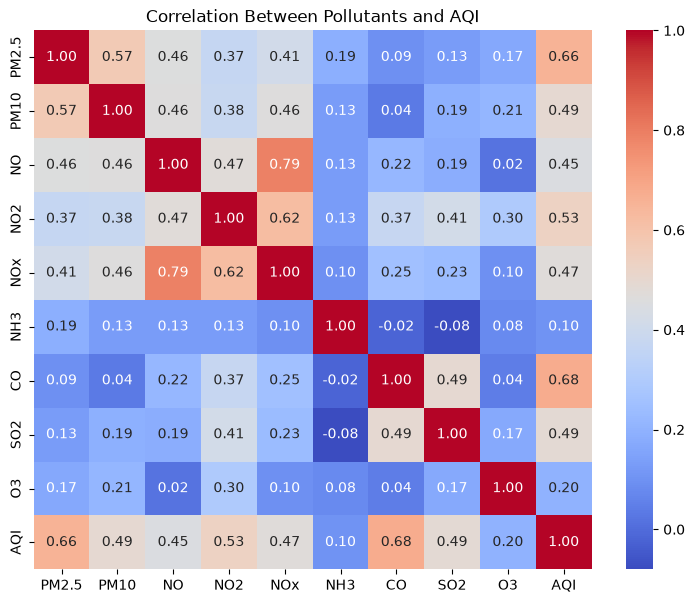

In [194]:
plt.figure(figsize=(9, 7))
sns.heatmap(table, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Pollutants and AQI")
plt.show()

**OBSERVATION:**

CO (0.68) and PM2.5 (0.66) have the strongest link with AQI. 

NH3 (0.10) and O3 (0.20) have the weakest.

In [195]:
cols = ["PM2.5", "PM10", "NO2", "CO", "SO2"]

fair = Lockdown_period_fair[Lockdown_period_fair["Year"].isin([2019, 2020])]
avg = fair.groupby("Year")[cols].mean()
pct_change = (avg.loc[2020] - avg.loc[2019]) / avg.loc[2019] * 100

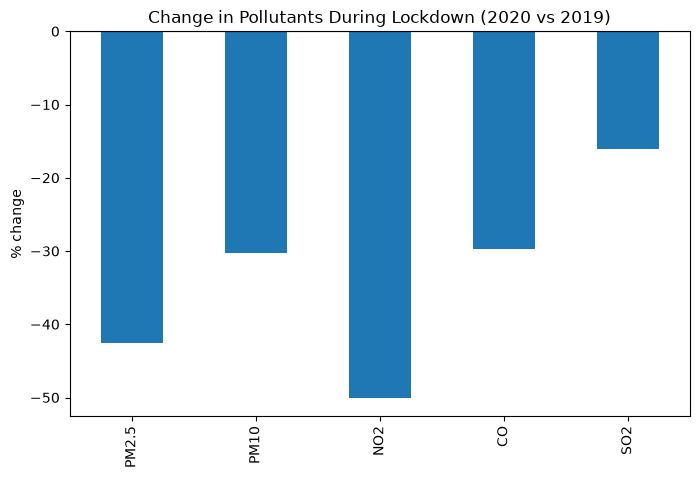

In [196]:

plt.figure(figsize=(8, 5))
pct_change.plot(kind="bar")
plt.title("Change in Pollutants During Lockdown (2020 vs 2019)")
plt.ylabel("% change")
plt.axhline(0, color="black")
plt.show()

**OBSERVATION:**

All five pollutants fell in 2020. NO2 fell the most (about 50%), then PM2.5 (about 42%). SO2 fell the least (about 16%).


## Conclusion

1. Worst cities: Ahmedabad, Delhi, Patna, Gurugram and Lucknow have the worst air quality.

2. Worst seasons: Winter and post-monsoon have the highest AQI. The monsoon has the lowest, because rain cleans the air.

3. Lockdown effect: The average AQI fell from 149.3 in 2019 to 89.8 in 2020, a drop of about 40%. So the lockdown did reduce pollution.

4. Pollutants: NO2 (about 50%) and PM2.5 (about 42%) fell the most during lockdown, which fits the drop in traffic and industry.

5. What drives AQI: CO and PM2.5 have the strongest link with AQI.

6. Air quality overall: Most days were Satisfactory or Moderate, and only a few days were Good or Severe.

## Limitations

-Ahmedabad has some extremely high AQI values, so I used the median to compare cities.

-Fewer cities had data in early 2015, so the first peak in the trend chart may not be fully reliable.